In [1]:
import pandas as pd 
ames = pd.read_csv('../data/ames.csv')
ames.head()

,MS_SubClass,MS_Zoning,Lot_Frontage,Lot_Area,Street,Alley,Lot_Shape,Land_Contour,Utilities,Lot_Config,...,Fence,Misc_Feature,Misc_Val,Mo_Sold,Year_Sold,Sale_Type,Sale_Condition,Sale_Price,Longitude,Latitude
0,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,141,31770,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,NaN,0,5,2010,WD,Normal,215000,-93.619754,42.054035
1,One_Story_1946_and_Newer_All_Styles,Residential_High_Density,80,11622,Pave,No_Alley_Access,Regular,Lvl,AllPub,Inside,...,Minimum_Privacy,NaN,0,6,2010,WD,Normal,105000,-93.619756,42.053014
2,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,81,14267,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Corner,...,No_Fence,Gar2,12500,6,2010,WD,Normal,172000,-93.619387,42.052659
3,One_Story_1946_and_Newer_All_Styles,Residential_Low_Density,93,11160,Pave,No_Alley_Access,Regular,Lvl,AllPub,Corner,...,No_Fence,NaN,0,4,2010,WD,Normal,244000,-93.617320,42.051245
4,Two_Story_1946_and_Newer,Residential_Low_Density,74,13830,Pave,No_Alley_Access,Slightly_Irregular,Lvl,AllPub,Inside,...,Minimum_Privacy,NaN,0,3,2010,WD,Normal,189900,-93.638933,42.060899


## Checking the Ames data for multicollinearity



In [4]:
# numeric predictors only (Sale_Price is the target, so leave it out)
num = ames.select_dtypes('number').drop(columns='Sale_Price').dropna()
num.shape

(2930, 34)

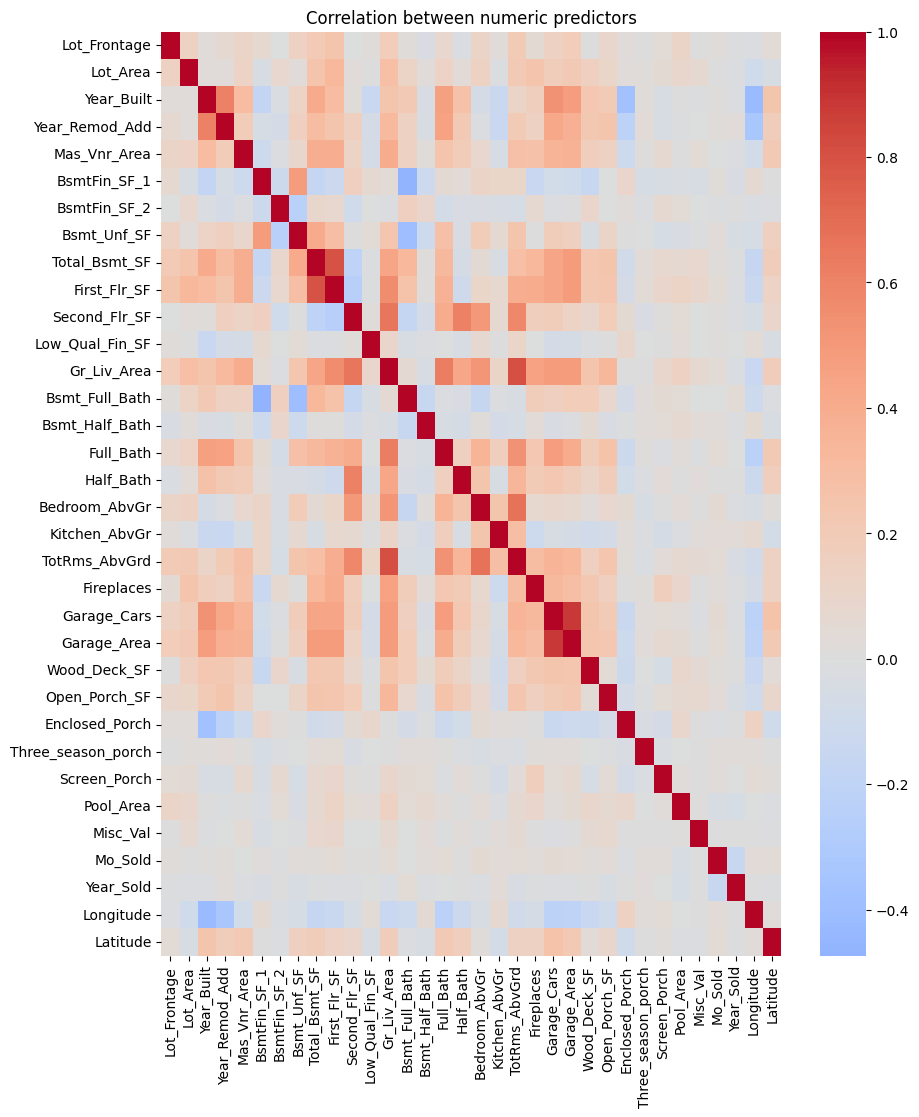

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

corr = num.corr()
plt.figure(figsize=(10, 12))
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.title('Correlation between numeric predictors')
plt.show()

In [13]:
import numpy as np

# keep only the upper triangle so each pair appears once, then list pairs with |r| > 0.7
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
pairs = upper.stack().loc[lambda s: s.abs() > 0.5].sort_values(key=abs, ascending=False)
pairs

Garage_Cars    Garage_Area       0.889866
Gr_Liv_Area    TotRms_AbvGrd     0.807772
Total_Bsmt_SF  First_Flr_SF      0.800429
Bedroom_AbvGr  TotRms_AbvGrd     0.672647
Second_Flr_SF  Gr_Liv_Area       0.655251
Gr_Liv_Area    Full_Bath         0.630321
Year_Built     Year_Remod_Add    0.612095
Second_Flr_SF  Half_Bath         0.611634
               TotRms_AbvGrd     0.585214
First_Flr_SF   Gr_Liv_Area       0.562166
Year_Built     Garage_Cars       0.537982
Full_Bath      TotRms_AbvGrd     0.528599
Gr_Liv_Area    Bedroom_AbvGr     0.516808
Second_Flr_SF  Bedroom_AbvGr     0.504651
dtype: float64

## I will use `Garage_Cars` , `Garage_Area` for this example because the plots show the greatest similarity.



In [12]:
sns.lmplot(
    data=ames, x="Garage_Cars", y="Sale_Price", hue="Garage_Area",
    height=6, aspect=1.4, scatter_kws={"alpha": 0.25}, ci=None,
)
plt.title("Sale Price vs. Garage Cars, by Garage Area")
plt.show()